In [1]:
import sys
sys.path.append('..')
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.cleaning import load_clean_orders
from src.rfm import compute_rfm, scale_rfm, find_best_k, fit_segments, label_segments

df = load_clean_orders()
rfm = compute_rfm(df)
rfm.describe()

,recency,frequency,monetary
count,93350.000000,93350.000000,93350.000000
mean,237.950070,1.033423,165.196388
std,152.589932,0.209106,226.322448
min,1.000000,1.000000,0.000000
25%,114.000000,1.000000,63.050000
50%,219.000000,1.000000,107.780000
75%,346.000000,1.000000,182.547500
max,714.000000,15.000000,13664.080000


   k        inertia  silhouette
0  2  190198.000173    0.710293
1  3  129147.881387    0.416934
2  4   82898.806210    0.393772
3  5   68325.176798    0.351822
4  6   58432.108162    0.350027
5  7   51227.640574    0.350646
6  8   45843.334675    0.345270


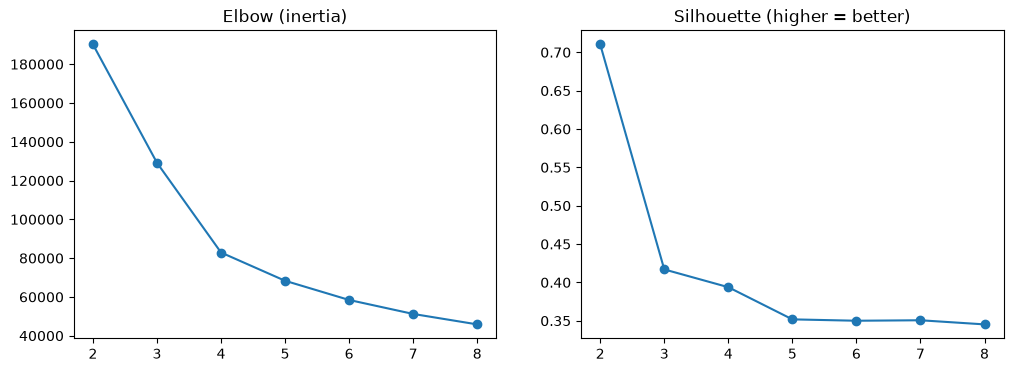

In [2]:
# Choose k: look for the elbow (where inertia stops dropping fast) and a high silhouette
X = scale_rfm(rfm)
ks = find_best_k(X)
print(ks)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks['k'], ks['inertia'], marker='o'); ax[0].set_title('Elbow (inertia)')
ax[1].plot(ks['k'], ks['silhouette'], marker='o'); ax[1].set_title('Silhouette (higher = better)')
plt.savefig('../reports/figures/kmeans_k_choice.png', dpi=150, bbox_inches='tight')
plt.show()

In [3]:
# Fit with your chosen k (5 is a sensible business choice; justify yours in a markdown cell)
K = 5
rfm['cluster'] = fit_segments(X, K)
profile = rfm.groupby('cluster').agg(
    customers=('customer_unique_id', 'count'),
    recency=('recency', 'mean'),
    frequency=('frequency', 'mean'),
    monetary=('monetary', 'mean'),
    total_revenue=('monetary', 'sum'),
).round(1)
profile['revenue_share_pct'] = (100 * profile['total_revenue'] / profile['total_revenue'].sum()).round(1)
profile

,customers,recency,frequency,monetary,total_revenue,revenue_share_pct
cluster,,,,,,
0,34536,290.9,1.0,144.1,4977184.2,32.3
1,28990,279.9,1.0,52.6,1526265.7,9.9
2,2801,220.3,2.1,308.6,864357.2,5.6
3,15476,41.3,1.0,123.9,1917807.7,12.4
4,11547,242.2,1.0,531.3,6135468.0,39.8


In [5]:
names = {0: 'At Risk / Lapsed', 1: 'Low-Value Lost', 2: 'Repeat Buyers', 3: 'Potential Loyalists', 4: 'High-Value One-timers'}
rfm = label_segments(rfm, names)
print(rfm['segment'].value_counts())
rfm.to_csv('../data/processed/customer_rfm.csv', index=False)

segment
At Risk / Lapsed         34536
Low-Value Lost           28990
Potential Loyalists      15476
High-Value One-timers    11547
Repeat Buyers             2801
Name: count, dtype: int64


In [6]:
rfm = pd.read_csv('../data/processed/customer_rfm.csv')
sc = pd.read_csv('../data/processed/customer_risk_scores.csv').drop(columns='segment')
sc = sc.merge(rfm[['customer_unique_id', 'segment']], on='customer_unique_id', how='left')
sc.to_csv('../data/processed/customer_risk_scores.csv', index=False)